# 03 · Where delay is created, how it spreads, and whether it heals

Notebook 02 showed *when* and *which trains*. This one follows delay through the
system: segment by segment along a trip, from one train to the next at a station,
and through the hours of a disrupted day. Clean subset, weekdays unless stated.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from common import q, connect, STATION_ORDER, wilson_halfwidth
from viz import BLUE, ORANGE, AQUA, RED, MUTED, GRID, SEQ, DIV, DIR_COLOR, SERVICE_COLOR, note

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
con = connect()
qq = lambda s: q(s, con)
ORD = {s: i for i, s in enumerate(STATION_ORDER)}

## 1. Segment accrual: where trains lose and gain time

For consecutive observed stops of the same trip, the change in delay is what happened
on that segment (running time plus the dwell at the first stop). Averaged over all
weekday runs, this is a map of where the timetable is tight (positive) and where it has
slack (negative).

In [2]:
seg = qq("""with s as (select date, trip_id, direction, service, sched_hour, station, stop_rank, delay_signed, sched_ts,
                 lead(station) over w nxt, lead(delay_signed) over w nd, lead(stop_rank) over w nr, lead(sched_ts) over w nts
              from clean where weekday window w as (partition by date, trip_id order by stop_rank))
            select direction, station, nxt, count(*) n, avg(nd-delay_signed) mean_delta, avg(((nd-delay_signed)>=2)::int) gain2,
                   avg(((nd-delay_signed)<=-1)::int) recover1, avg(epoch(nts-sched_ts))/60 sched_min
            from s where nr=stop_rank+1 group by 1,2,3 having count(*)>=2000 order by direction, mean_delta desc""")
seg["from_ord"] = seg.station.map(ORD); seg["to_ord"] = seg.nxt.map(ORD)
seg.round(2).head(12)

,direction,station,nxt,n,mean_delta,gain2,recover1,sched_min,from_ord,to_ord
0,NB,South San Francisco,22nd Street,3228,1.31,0.30,0.00,7.54,3,1
1,NB,Millbrae,San Bruno,4894,0.87,0.04,0.00,3.00,5,4
2,NB,Hillsdale,San Mateo,3396,0.82,0.12,0.00,3.00,10,8
3,NB,South San Francisco,Bayshore,4060,0.77,0.04,0.00,5.00,3,2
4,NB,San Carlos,Belmont,5722,0.76,0.04,0.01,2.02,12,11
5,NB,Hayward Park,San Mateo,6131,0.74,0.05,0.00,2.02,9,8
6,NB,Lawrence,Sunnyvale,7938,0.61,0.02,0.01,3.02,21,20
7,NB,San Antonio,California Avenue,7455,0.43,0.02,0.01,3.00,18,17
8,NB,San Mateo,Burlingame,6981,0.41,0.03,0.05,2.98,8,7
9,NB,Mountain View,San Antonio,8132,0.21,0.02,0.06,3.00,19,18


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


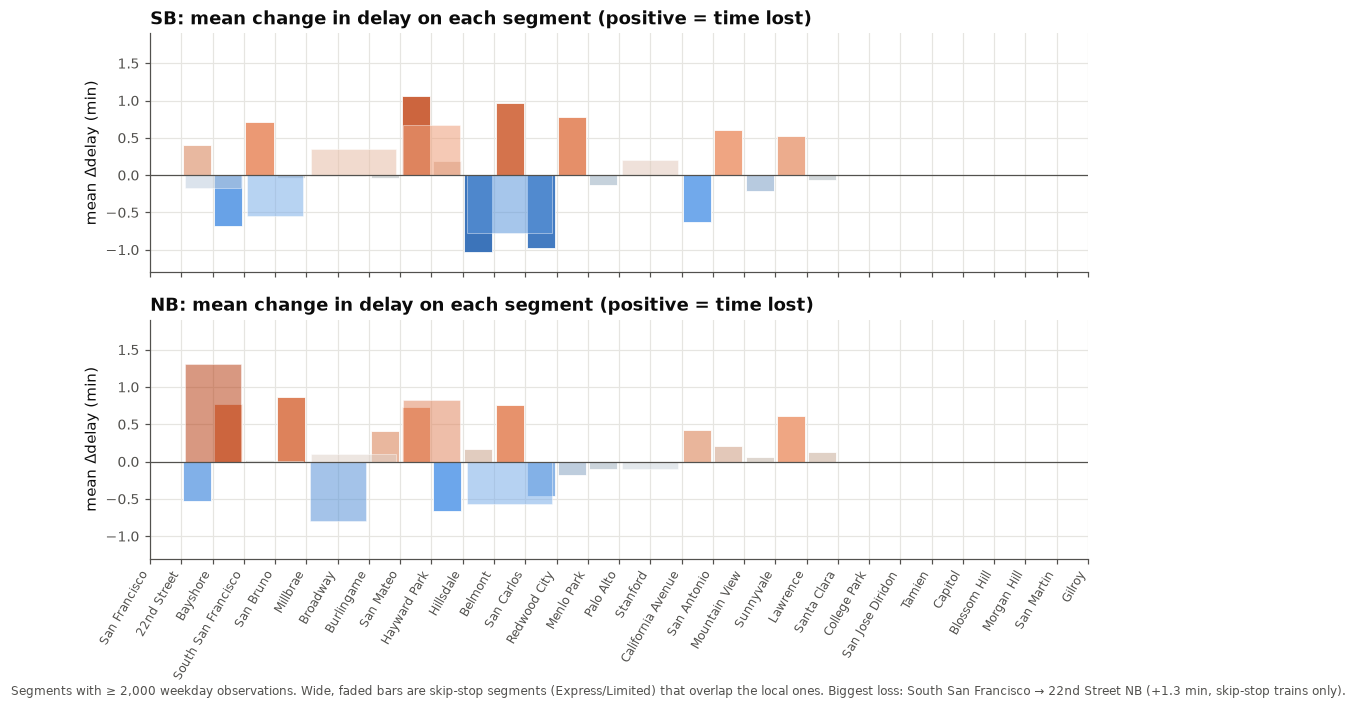

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True)
for ax, d in zip(axes, ["SB", "NB"]):
    g = seg[seg.direction == d].sort_values("from_ord")
    x = (g.from_ord + g.to_ord) / 2
    colors = [DIV(0.5 + np.clip(v, -1.3, 1.3) / 2.6) for v in g.mean_delta]
    span = np.abs(g.to_ord - g.from_ord)
    for wide, alpha in ((False, 1.0), (True, 0.55)):
        sel = (span > 1) == wide
        ax.bar(x[sel], g.mean_delta[sel], width=span[sel] * 0.9, color=[c for c, m in zip(colors, sel) if m],
               edgecolor="white", lw=0.5, alpha=alpha)
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_ylim(-1.3, 1.9); ax.set_ylabel("mean Δdelay (min)")
    ax.set_title(f"{d}: mean change in delay on each segment (positive = time lost)")
axes[1].set_xticks(range(len(STATION_ORDER))); axes[1].set_xticklabels(STATION_ORDER, rotation=60, ha="right", fontsize=8)
fig.text(0.01, -0.09, "Segments with ≥ 2,000 weekday observations. Wide, faded bars are skip-stop segments (Express/Limited) that overlap the local ones. "
                     "Biggest loss: South San Francisco → 22nd Street NB (+1.3 min, skip-stop trains only).", fontsize=8, color=MUTED)
plt.show()

Northbound: the final approach into San Francisco is the single biggest time sink.
Trains that skip Bayshore (Express and Limited) are given 7.5 minutes from South San
Francisco to 22nd Street and lose 1.3 minutes on average; Express trains gain ≥ 2
minutes there on 43% of runs. Locals, which have an extra 2.5 minutes of running time
through Bayshore, recover on the same stretch.

In [4]:
qq("""with s as (select date, trip_id, direction, service, sched_hour, station, stop_rank, delay_signed,
             lead(station) over w nxt, lead(delay_signed) over w nd, lead(stop_rank) over w nr
          from clean where weekday window w as (partition by date, trip_id order by stop_rank))
      select service, station || ' → ' || nxt segment, count(*) n, round(avg(nd-delay_signed),2) mean_delta,
             round(avg(((nd-delay_signed)>=2)::int),3) share_gain_2min
      from s where direction='NB' and nxt='22nd Street' and nr=stop_rank+1 group by 1,2 order by 1""")

,service,segment,n,mean_delta,share_gain_2min
0,Express,South San Francisco → 22nd Street,1495,1.70,0.431
1,Limited,South San Francisco → 22nd Street,1733,0.97,0.180
2,Local,Bayshore → 22nd Street,5166,-0.53,0.009


## 2. Where do trains *first* become late?

The stop at which a trip first crosses 5 minutes late. Northbound onsets cluster at the
San Francisco approach (22nd Street + Bayshore = 28% of all NB onsets). Southbound
onsets are spread along the mid-Peninsula (Menlo Park, California Avenue, Mountain
View, San Carlos), each with a small jump: delay there is accumulated, not caused by a
single bottleneck.

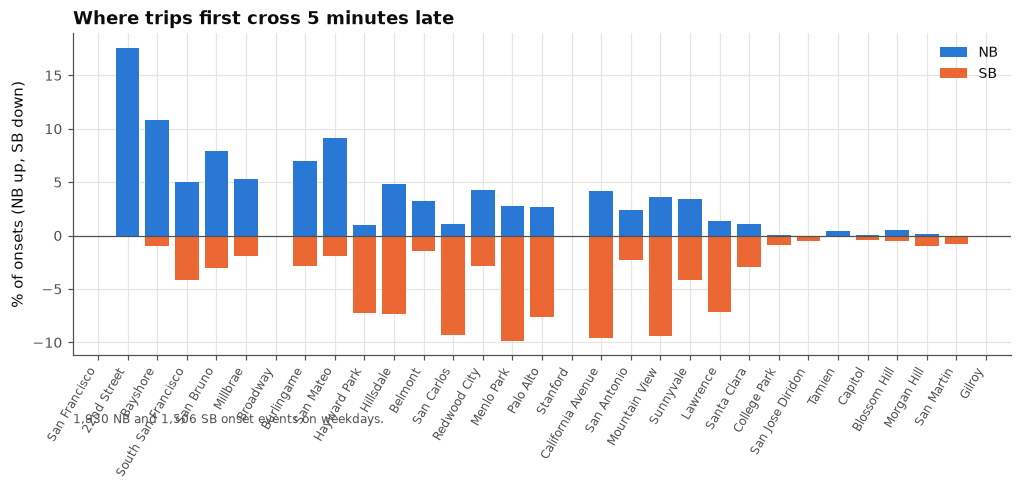

In [5]:
onset = qq("""with t as (select date, trip_id, direction, station, stop_rank, delay_signed,
                   lag(delay_signed) over (partition by date, trip_id order by stop_rank) prev from clean where weekday)
              select direction, station, count(*) onsets, avg(delay_signed-prev) mean_jump from t where delay_signed>5 and prev<=5 group by 1,2""")
onset["pct"] = onset.onsets / onset.groupby("direction").onsets.transform("sum") * 100
onset["ord"] = onset.station.map(ORD)
fig, ax = plt.subplots(figsize=(11, 3.8))
for d, sgn in (("NB", 1), ("SB", -1)):
    g = onset[onset.direction == d].sort_values("ord")
    ax.bar(g.ord, sgn * g.pct, color=DIR_COLOR[d], label=d, width=0.8)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(range(len(STATION_ORDER))); ax.set_xticklabels(STATION_ORDER, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("% of onsets (NB up, SB down)"); ax.set_title("Where trips first cross 5 minutes late")
ax.legend(); note(ax, f"{int(onset[onset.direction=='NB'].onsets.sum()):,} NB and {int(onset[onset.direction=='SB'].onsets.sum()):,} SB onset events on weekdays.")
plt.show()

## 3. Knock-on between consecutive trains: headway is the gate

At a station, compare each train's delay with the delay of the previous same-direction
train. A late leader makes a late follower, but only when the scheduled headway is
shorter than the leader's delay: with a 10–20-minute-late leader, the follower is late
88% of the time at ≤ 10-minute headways and 34% at 21–30-minute headways.

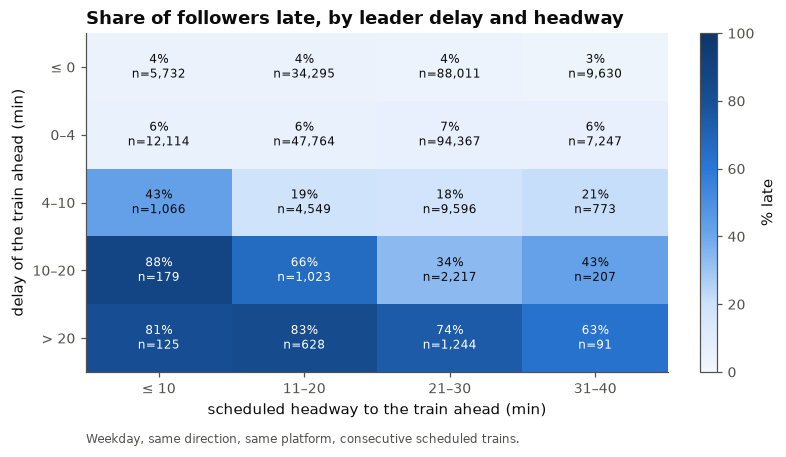

In [6]:
kn = qq("""with s as (select date, stop_id, trip_id, service, sched_ts, delay_signed, late4,
                lag(delay_signed) over w lead_delay, lag(sched_ts) over w lead_sched
             from clean where weekday window w as (partition by date, stop_id order by sched_ts))
           select case when lead_delay<=0 then '≤ 0' when lead_delay<=4 then '0–4' when lead_delay<=10 then '4–10' when lead_delay<=20 then '10–20' else '> 20' end leader_delay,
                  case when hw<=10 then '≤ 10' when hw<=20 then '11–20' when hw<=30 then '21–30' else '31–40' end headway,
                  count(*) n, avg(late4::int) follower_late4, median(delay_signed) follower_median
           from (select *, epoch(sched_ts-lead_sched)/60 hw from s) where lead_delay is not null and hw<=40 group by 1,2""")
lorder = ["≤ 0", "0–4", "4–10", "10–20", "> 20"]; horder = ["≤ 10", "11–20", "21–30", "31–40"]
piv = kn.pivot(index="leader_delay", columns="headway", values="follower_late4").reindex(index=lorder, columns=horder) * 100
npiv = kn.pivot(index="leader_delay", columns="headway", values="n").reindex(index=lorder, columns=horder)
fig, ax = plt.subplots(figsize=(7.5, 4))
im = ax.imshow(piv.values, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v, n = piv.values[i, j], npiv.values[i, j]
        ax.text(j, i, f"{v:.0f}%\nn={int(n):,}", ha="center", va="center", fontsize=8, color="white" if v > 55 else "#0b0b0b")
ax.set_xticks(range(4)); ax.set_xticklabels(horder); ax.set_yticks(range(5)); ax.set_yticklabels(lorder); ax.grid(False)
ax.set_xlabel("scheduled headway to the train ahead (min)"); ax.set_ylabel("delay of the train ahead (min)")
ax.set_title("Share of followers late, by leader delay and headway"); plt.colorbar(im, ax=ax, label="% late", fraction=0.04)
note(ax, "Weekday, same direction, same platform, consecutive scheduled trains.")
plt.show()

### Express trains inherit the local ahead
At 22nd Street northbound, an Express whose leader is more than 6 minutes late is itself
late 88% of the time; a Local in the same situation 38% of the time, because locals
typically have 25+ minutes of headway while expresses run ~10 minutes behind a local.
Even with an on-time leader an Express is late 20% of the time (vs 10% for a Local).

In [7]:
qq("""with s as (select date, stop_id, station, direction, trip_id, service, sched_ts, delay_signed, late4,
             lag(delay_signed) over w lead_delay, lag(sched_ts) over w lead_sched
          from clean where weekday window w as (partition by date, stop_id order by sched_ts))
      select service, case when lead_delay<=2 then 'leader ≤ 2 min' when lead_delay<=6 then 'leader 2–6 min' else 'leader > 6 min' end leader,
             count(*) n, round(avg(late4::int),3) late4, round(median(delay_signed),1) median_delay, round(avg(epoch(sched_ts-lead_sched))/60,1) mean_headway
      from s where direction='NB' and station='22nd Street' and lead_delay is not null and epoch(sched_ts-lead_sched)/60<=30 group by 1,2 order by 1,2""")

,service,leader,n,late4,median_delay,mean_headway
0,Express,leader 2–6 min,463,0.393,3.9,10.2
1,Express,leader > 6 min,125,0.880,7.8,10.8
2,Express,leader ≤ 2 min,1004,0.202,2.0,9.8
3,Limited,leader 2–6 min,414,0.147,2.0,8.2
4,Limited,leader > 6 min,122,0.877,7.0,8.3
5,Limited,leader ≤ 2 min,967,0.089,0.9,10.3
6,Local,leader 2–6 min,1756,0.166,1.8,26.4
7,Local,leader > 6 min,559,0.385,2.9,26.0
8,Local,leader ≤ 2 min,3859,0.098,0.9,27.3


## 4. Delays do not heal within a trip

Take every weekday trip that first reaches ≥ 10 minutes late at some stop and follow it.
Over the next ten stops the median change is zero to plus one minute; only ~8% recover
two or more minutes and ~40% get two or more minutes worse. Essentially none get back
under the 4-minute threshold. Once a train is properly late, it stays late to the end.

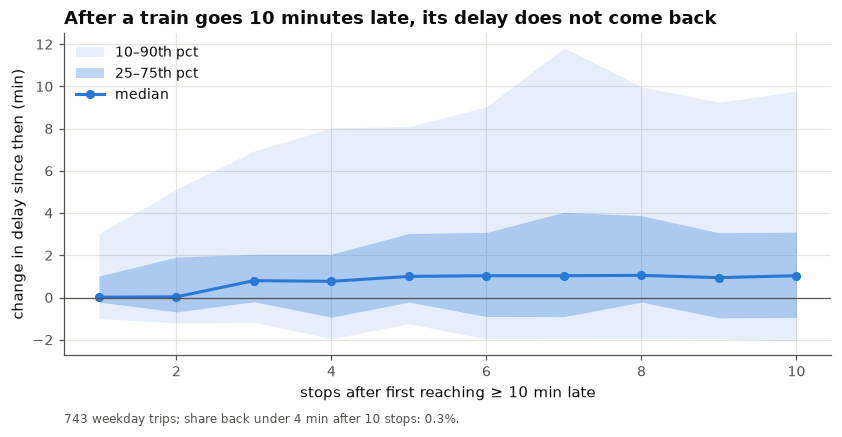

In [8]:
rec = qq("""with t as (select date, trip_id, direction, service, stop_rank, n_stops, delay_signed,
                 min(case when delay_signed>=10 then stop_rank end) over (partition by date, trip_id) first10 from clean where weekday),
            base as (select date, trip_id, delay_signed d0, stop_rank r0 from t where stop_rank=first10),
            later as (select t.direction, t.service, t.stop_rank-base.r0 k, t.delay_signed-base.d0 dd, t.delay_signed d
                      from t join base using(date, trip_id) where t.stop_rank>base.r0)
            select k, count(*) n, median(dd) med, quantile_cont(dd,0.25) p25, quantile_cont(dd,0.75) p75, quantile_cont(dd,0.1) p10, quantile_cont(dd,0.9) p90,
                   avg((dd<=-2)::int) recovered2, avg((dd>=2)::int) worsened2, avg((d<=4)::int) back_on_time
            from later where k<=10 group by 1 order by 1""")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(rec.k, rec.p10, rec.p90, color=BLUE, alpha=0.12, lw=0, label="10–90th pct")
ax.fill_between(rec.k, rec.p25, rec.p75, color=BLUE, alpha=0.3, lw=0, label="25–75th pct")
ax.plot(rec.k, rec.med, color=BLUE, marker="o", label="median")
ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel("stops after first reaching ≥ 10 min late"); ax.set_ylabel("change in delay since then (min)")
ax.set_title("After a train goes 10 minutes late, its delay does not come back"); ax.legend(loc="upper left")
note(ax, f"{int(rec.n.max()):,} weekday trips; share back under 4 min after 10 stops: {rec.back_on_time.iloc[-1]:.1%}.")
plt.show()

In [9]:
rec.round(2)

,k,n,med,p25,p75,p10,p90,recovered2,worsened2,back_on_time
0,1,743,0.02,-0.22,1.02,-1.00,3.02,0.02,0.17,0.0
1,2,717,0.03,-0.68,1.92,-1.20,5.13,0.04,0.25,0.0
2,3,651,0.80,-0.20,2.05,-1.17,6.93,0.05,0.30,0.0
3,4,595,0.77,-0.93,2.05,-1.95,8.03,0.08,0.31,0.0
4,5,528,1.00,-0.22,3.03,-1.24,8.10,0.05,0.38,0.0
5,6,513,1.03,-0.90,3.08,-1.97,9.03,0.08,0.38,0.0
6,7,464,1.03,-0.90,4.04,-1.95,11.83,0.08,0.40,0.0
7,8,414,1.05,-0.22,3.88,-1.93,9.98,0.07,0.40,0.0
8,9,334,0.94,-0.96,3.07,-1.97,9.25,0.09,0.38,0.0
9,10,302,1.03,-0.95,3.10,-2.03,9.77,0.11,0.40,0.0


In [10]:
qq("""with t as (select date, trip_id, direction, service, stop_rank, delay_signed,
             min(case when delay_signed>=10 then stop_rank end) over (partition by date, trip_id) first10 from clean where weekday),
        base as (select date, trip_id, delay_signed d0, stop_rank r0 from t where stop_rank=first10),
        later as (select t.direction, t.service, t.stop_rank-base.r0 k, t.delay_signed-base.d0 dd from t join base using(date, trip_id) where t.stop_rank>base.r0)
      select direction, service, count(*) n, round(median(dd),1) median_change_5_stops_later, round(avg((dd<=-2)::int),3) recovered2, round(avg((dd>=2)::int),3) worsened2
      from later where k=5 group by 1,2 order by 1,2""")

,direction,service,n,median_change_5_stops_later,recovered2,worsened2
0,NB,Express,68,2.0,0.044,0.559
1,NB,Limited,48,2.0,0.021,0.542
2,NB,Local,188,1.0,0.027,0.351
3,SB,Express,15,-0.9,0.267,0.200
4,SB,Limited,35,1.1,0.057,0.429
5,SB,Local,174,0.1,0.069,0.305


## 5. Big delays are rare, concentrated, and take an afternoon to clear

Half of all service days have two or fewer arrivals more than 15 minutes late. Ten days
(2.6% of days) account for a third of all such arrivals. On those days the system goes
from normal to a median delay of 20–60 minutes within an hour and takes four to six
hours to return to normal.

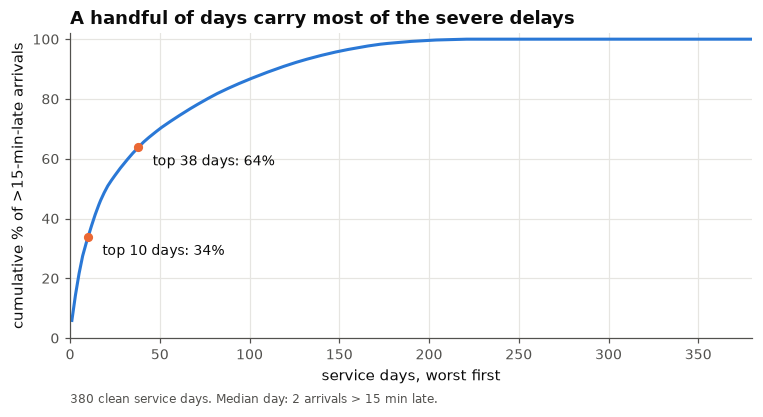

In [11]:
conc = qq("""with d as (select date, sum(late15::int) l15 from clean group by 1), r as (select *, row_number() over (order by l15 desc) rk from d)
             select rk, date, l15, sum(l15) over (order by rk)*100.0/sum(l15) over () cum_pct from r order by rk""")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(conc.rk, conc.cum_pct, color=BLUE)
for k in (10, 38):
    y = conc.loc[conc.rk == k, "cum_pct"].iloc[0]
    ax.plot([k], [y], "o", color=ORANGE); ax.annotate(f"top {k} days: {y:.0f}%", (k, y), xytext=(k + 8, y - 6), fontsize=9)
ax.set_xlabel("service days, worst first"); ax.set_ylabel("cumulative % of >15-min-late arrivals")
ax.set_title("A handful of days carry most of the severe delays"); ax.set_xlim(0, 380); ax.set_ylim(0, 102)
note(ax, "380 clean service days. Median day: 2 arrivals > 15 min late.")
plt.show()

In [12]:
worst = qq("""select date, dow, count(*) n, round(avg(late4::int),3) late4, round(avg(late15::int),3) late15, round(avg(delay_signed),1) mean_delay,
                     round(max(delay_signed)) max_delay, count(distinct case when late15 then trip_id end) trains_over_15
              from clean group by 1,2 order by late15 desc limit 12""")
worst

,date,dow,n,late4,late15,mean_delay,max_delay,trains_over_15
0,2025-11-06,4,1349,0.284,0.241,13.5,92.0,37
1,2026-01-03,6,1014,0.328,0.193,6.8,45.0,25
2,2025-10-24,5,1311,0.242,0.183,7.2,58.0,28
3,2025-08-18,1,1346,0.241,0.169,7.2,77.0,27
4,2026-01-11,7,1095,0.222,0.147,5.9,65.0,20
5,2026-03-19,4,1372,0.198,0.144,5.9,66.0,27
6,2025-08-27,3,1474,0.216,0.111,4.6,43.0,23
7,2026-03-14,6,993,0.207,0.104,5.1,61.0,11
8,2025-10-04,6,1106,0.392,0.090,5.0,23.0,18
9,2026-06-22,1,1237,0.192,0.088,6.1,87.0,20


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


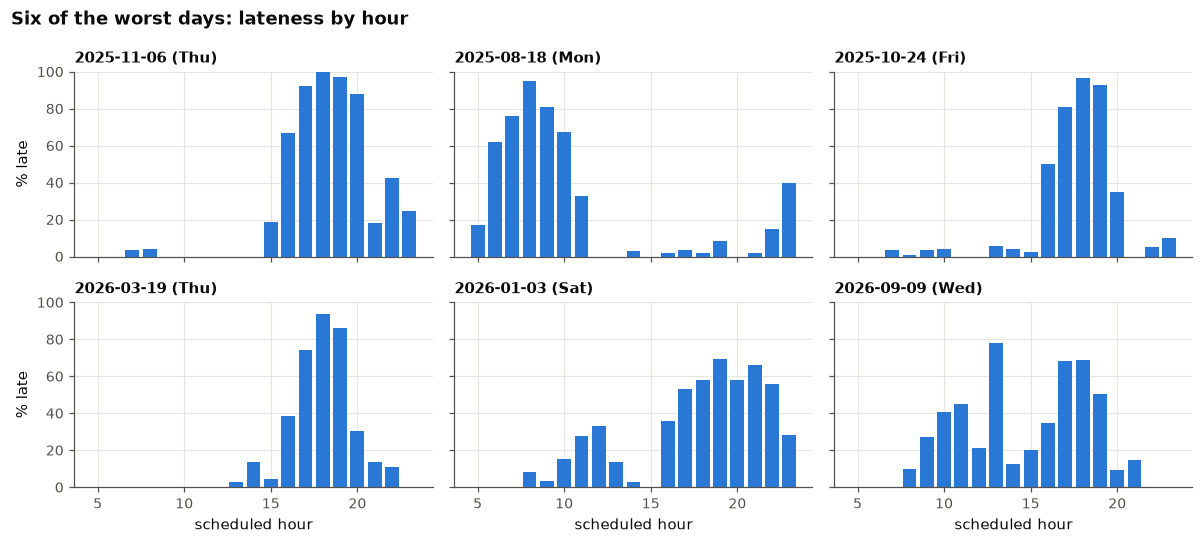

In [13]:
days = ["2025-11-06", "2025-08-18", "2025-10-24", "2026-03-19", "2026-01-03", "2026-09-09"]
prof = qq(f"""select date, sched_hour, count(*) n, avg(late4::int) late4, median(delay_signed) med from clean
              where date in ({",".join("'"+d+"'" for d in days)}) and sched_hour between 5 and 23 group by 1,2 order by 1,2""")
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, sharey=True)
for ax, d in zip(axes.flat, days):
    g = prof[prof.date.astype(str) == d]
    ax.bar(g.sched_hour, g.late4 * 100, color=BLUE, width=0.8)
    ax.set_title(f"{d} ({['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][pd.Timestamp(d).dayofweek]})", fontsize=10)
    ax.set_ylim(0, 100)
for ax in axes[1]: ax.set_xlabel("scheduled hour")
for ax in axes[:, 0]: ax.set_ylabel("% late")
fig.suptitle("Six of the worst days: lateness by hour", x=0.01, ha="left", fontsize=12, fontweight="semibold")
plt.tight_layout(); plt.show()

A day-level recovery statistic: for each of the 20 worst days, the number of hours from
the first hour with > 50% of arrivals late to the first subsequent hour under 15%.

In [14]:
qq("""with h as (select date, sched_hour, avg(late4::int) late4 from clean where sched_hour between 5 and 23 group by 1,2),
         w as (select date from (select date, avg(late15::int) l15 from clean group by 1 order by l15 desc limit 20)),
         s as (select h.date, min(case when late4>0.5 then sched_hour end) start_h from h join w using(date) group by 1),
         e as (select s.date, s.start_h, min(case when h.sched_hour>s.start_h and late4<0.15 then h.sched_hour end) end_h from s join h using(date) group by 1,2)
      select count(*) ndays, round(avg(end_h-start_h),1) mean_hours_to_recover, median(end_h-start_h) median_hours, min(end_h-start_h) mn, max(end_h-start_h) mx from e where start_h is not null""")

,ndays,mean_hours_to_recover,median_hours,mn,mx
0,18,3.8,4.0,1,6
